In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, recall_score,
                             precision_score, f1_score, roc_auc_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)
from sklearn.cluster import KMeans
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 11,
    'axes.titlesize': 12, 'axes.labelsize': 11, 'legend.frameon': False})
NAT, MAN, NEU, PUR, GRY = 'blue', 'red', 'green', 'purple', 'gray'
SEED = 42
FIG = 'figures_results'
os.makedirs(FIG, exist_ok=True)

def save(name):
    plt.savefig(f'{FIG}/{name}.png', dpi=200, bbox_inches='tight')
    plt.show()

In [ ]:
candidates = []
try:
    from google.colab import drive
    drive.mount('/content/drive')
    candidates.append('/content/drive/MyDrive/DATA 490-Capstone Project')
except Exception:
    pass
candidates += ['/content', '.', 'data']

path = None
for d in candidates:
    p = os.path.join(d, 'seismic_model_table.csv')
    if os.path.exists(p):
        path = p
        break
if path is None:
    raise FileNotFoundError('Put seismic_model_table.csv in the Drive folder DATA 490-Capstone Project.')

df = pd.read_csv(path)
print('Using:', path)
print('Rows:', df.shape[0], ' Columns:', df.shape[1], ' Missing values:', int(df.isnull().sum().sum()))
print('Earthquakes:', int((df['is_manmade'] == 0).sum()), ' Human caused:', int(df['is_manmade'].sum()))

Mounted at /content/drive
Using: /content/drive/MyDrive/DATA 490-Capstone Project/seismic_model_table.csv
Rows: 33181  Columns: 8  Missing values: 0
Earthquakes: 30440  Human caused: 2741


In [ ]:
xy = df[['latitude', 'longitude']].values
km = KMeans(n_clusters=8, n_init=10, random_state=SEED).fit(xy)
df['cluster'] = km.labels_
center_lon = df.groupby('cluster')['longitude'].mean().sort_values()
group_no = {c: i + 1 for i, c in enumerate(center_lon.index)}
df['group'] = df['cluster'].map(group_no)
print(df.groupby('group').agg(events=('depth', 'size'), human_caused=('is_manmade', 'sum'),
                              human_percent=('is_manmade', lambda s: round(s.mean() * 100, 1)),
                              median_depth=('depth', 'median')))

YEARS = sorted(df['year'].unique())
GROUPS = sorted(df['group'].unique())
FEAT_DEPTH = ['latitude', 'longitude', 'mag', 'year', 'month', 'hour']
FEAT_DEPTH_SHORT = ['latitude', 'longitude', 'mag', 'hour']
FEAT_TYPE = ['latitude', 'longitude', 'mag', 'month', 'hour']
year_cv = GroupKFold(n_splits=3)

def tune(model, grid, X, y, groups, scoring):
    if not grid:
        return clone(model).fit(X, y)
    gs = GridSearchCV(model, grid, cv=year_cv, scoring=scoring, n_jobs=-1)
    gs.fit(X, y, groups=groups)
    return gs.best_estimator_

def rf_reg():
    return RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED)

def rf_clf():
    return RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)

def depth_scores(y, p):
    return [mean_absolute_error(y, p), np.sqrt(mean_squared_error(y, p)), r2_score(y, p)]

       events  human_caused  human_percent  median_depth
group                                                   
1        5769           119            2.1        4.4710
2        7637           261            3.4        5.5440
3        3871            24            0.6        5.6000
4        7216           346            4.8        4.2380
5        4896            60            1.2        6.7065
6        2217           463           20.9        3.5600
7         689           604           87.7        0.0000
8         886           864           97.5        0.0000


In [ ]:
grid_rf = {'min_samples_leaf': [5, 20]}
rows, pred_full, pred_short, pred_base = [], {}, {}, {}
for yr in YEARS:
    tr, te = df[df['year'] != yr], df[df['year'] == yr]
    m6 = tune(rf_reg(), grid_rf, tr[FEAT_DEPTH], tr['depth'], tr['year'], 'neg_mean_absolute_error')
    m4 = tune(rf_reg(), grid_rf, tr[FEAT_DEPTH_SHORT], tr['depth'], tr['year'], 'neg_mean_absolute_error')
    base = DummyRegressor(strategy='median').fit(tr[FEAT_DEPTH], tr['depth'])
    p6, p4, pb = m6.predict(te[FEAT_DEPTH]), m4.predict(te[FEAT_DEPTH_SHORT]), base.predict(te[FEAT_DEPTH])
    pred_full[yr], pred_short[yr], pred_base[yr] = pd.Series(p6, te.index), pd.Series(p4, te.index), pd.Series(pb, te.index)
    rows.append(['Random Forest, six predictors', yr] + depth_scores(te['depth'], p6))
    rows.append(['Random Forest, no month and year', yr] + depth_scores(te['depth'], p4))
    rows.append(['Baseline median', yr] + depth_scores(te['depth'], pb))
depth_year = pd.DataFrame(rows, columns=['model', 'held_out_year', 'MAE', 'RMSE', 'R2'])
print('Depth, leave one year out. Mean and standard deviation over the six held out years')
print(depth_year.groupby('model')[['MAE', 'RMSE', 'R2']].agg(['mean', 'std']).round(3))
print(depth_year.pivot(index='held_out_year', columns='model', values='MAE').round(2))

pf = pd.concat(pred_full.values()).sort_index()
err_year = (pf - df['depth']).abs()
print('\nMAE of the six predictor model, earthquakes:', round(err_year[df['is_manmade'] == 0].mean(), 3),
      ' human caused:', round(err_year[df['is_manmade'] == 1].mean(), 3))

Depth, leave one year out. Mean and standard deviation over the six held out years
                                    MAE          RMSE            R2       
                                   mean    std   mean    std   mean    std
model                                                                     
Baseline median                   3.913  0.253  5.924  0.228 -0.034  0.028
Random Forest, no month and year  2.289  0.145  4.008  0.343  0.526  0.054
Random Forest, six predictors     2.325  0.168  4.028  0.355  0.522  0.056
model          Baseline median  Random Forest, no month and year  \
held_out_year                                                      
2000                      3.92                              2.42   
2001                      4.12                              2.16   
2002                      4.11                              2.15   
2003                      3.84                              2.32   
2004                      3.45                             

In [7]:
eq = df[df['is_manmade'] == 0]
rows = []
pred_eq_only = {}
for yr in YEARS:
    tr_all, te = df[df['year'] != yr], eq[eq['year'] == yr]
    tr_eq = eq[eq['year'] != yr]
    m_all = tune(rf_reg(), grid_rf, tr_all[FEAT_DEPTH], tr_all['depth'], tr_all['year'], 'neg_mean_absolute_error')
    m_eq = tune(rf_reg(), grid_rf, tr_eq[FEAT_DEPTH], tr_eq['depth'], tr_eq['year'], 'neg_mean_absolute_error')
    base = DummyRegressor(strategy='median').fit(tr_eq[FEAT_DEPTH], tr_eq['depth'])
    pe = m_eq.predict(te[FEAT_DEPTH])
    pred_eq_only[yr] = pd.Series(pe, te.index)
    rows.append(['Baseline median (earthquakes)', yr] + depth_scores(te['depth'], base.predict(te[FEAT_DEPTH])))
    rows.append(['Random Forest trained on all events', yr] + depth_scores(te['depth'], m_all.predict(te[FEAT_DEPTH])))
    rows.append(['Random Forest trained on earthquakes only', yr] + depth_scores(te['depth'], pe))
depth_eq = pd.DataFrame(rows, columns=['model', 'held_out_year', 'MAE', 'RMSE', 'R2'])
print('Depth of earthquakes only. Mean and standard deviation over the six held out years')
print(depth_eq.groupby('model')[['MAE', 'RMSE', 'R2']].agg(['mean', 'std']).round(3))

pe_all = pd.concat(pred_eq_only.values()).sort_index()
e_eq = (pe_all - eq['depth']).abs()
ten = np.isclose(eq['depth'], 10.0)
print('\nEarthquakes with a depth of exactly 10 km:', int(ten.sum()), 'of', len(eq), f'({ten.mean() * 100:.1f} percent)')
print('Earthquake only model, error on depth 10 km events:', round(e_eq[ten].mean(), 2), ' on all other earthquakes:', round(e_eq[~ten].mean(), 2))

Depth of earthquakes only. Mean and standard deviation over the six held out years
                                             MAE          RMSE           R2  \
                                            mean    std   mean   std   mean   
model                                                                         
Baseline median (earthquakes)              3.761  0.206  5.829  0.22 -0.041   
Random Forest trained on all events        2.467  0.189  4.098  0.34  0.486   
Random Forest trained on earthquakes only  2.447  0.209  4.083  0.36  0.490   

                                                  
                                             std  
model                                             
Baseline median (earthquakes)              0.040  
Random Forest trained on all events        0.050  
Random Forest trained on earthquakes only  0.052  

Earthquakes with a depth of exactly 10 km: 303 of 30440 (1.0 percent)
Earthquake only model, error on depth 10 km events: 0.81  on all 

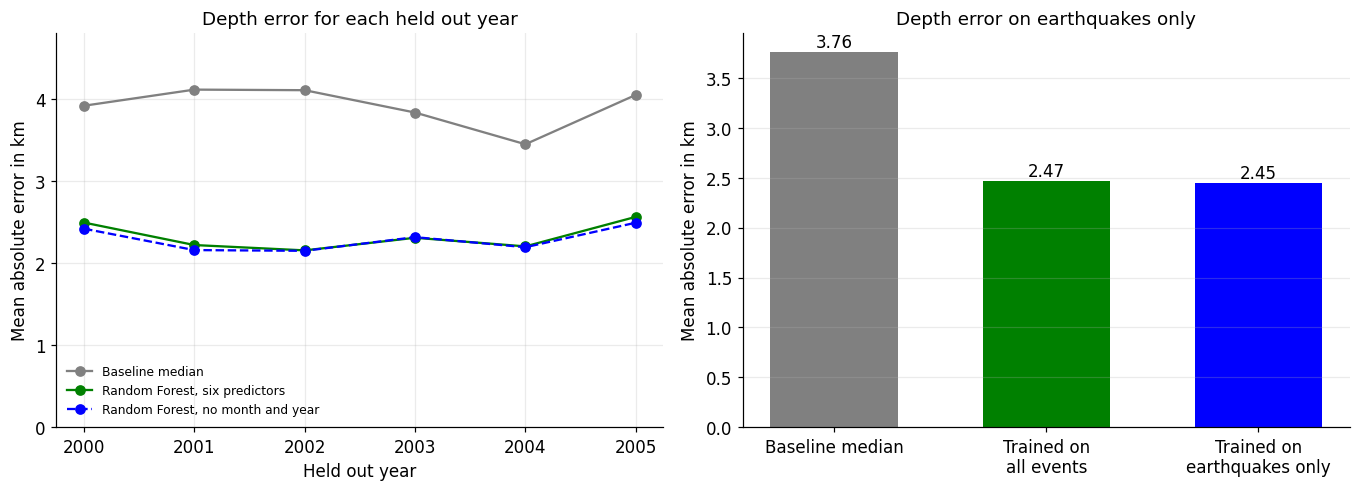

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
piv = depth_year.pivot(index='held_out_year', columns='model', values='MAE')
for name, col, ls in [('Baseline median', GRY, '-'), ('Random Forest, six predictors', NEU, '-'),
                      ('Random Forest, no month and year', NAT, '--')]:
    ax[0].plot(piv.index, piv[name], marker='o', color=col, ls=ls, label=name)
ax[0].set_xlabel('Held out year'); ax[0].set_ylabel('Mean absolute error in km')
ax[0].set_title('Depth error for each held out year'); ax[0].set_ylim(0, 4.8); ax[0].legend(fontsize=8)
order = ['Baseline median (earthquakes)', 'Random Forest trained on all events', 'Random Forest trained on earthquakes only']
vals = [depth_eq[depth_eq['model'] == k]['MAE'].mean() for k in order]
ax[1].bar(['Baseline median', 'Trained on\nall events', 'Trained on\nearthquakes only'], vals, color=[GRY, NEU, NAT], width=0.6)
for i, v in enumerate(vals):
    ax[1].text(i, v + 0.05, f'{v:.2f}', ha='center')
ax[1].set_ylabel('Mean absolute error in km'); ax[1].set_title('Depth error on earthquakes only'); ax[1].grid(axis='x', alpha=0)
plt.tight_layout(); save('fig01_depth_final')

In [9]:
ratio = lambda y: float((y == 0).sum() / max((y == 1).sum(), 1))
rows, probs = [], {'Naive Bayes': [], 'Random Forest': [], 'XGBoost': []}
for yr in YEARS:
    tr, te = df[df['year'] != yr], df[df['year'] == yr]
    Xtr, ytr, Xte, yte = tr[FEAT_TYPE], tr['is_manmade'], te[FEAT_TYPE], te['is_manmade']
    models = {
        'Naive Bayes': clone(GaussianNB()).fit(Xtr, ytr),
        'Random Forest': tune(rf_clf(), {'min_samples_leaf': [1, 5]}, Xtr, ytr, tr['year'], 'average_precision'),
        'XGBoost': tune(XGBClassifier(n_estimators=150, learning_rate=0.05, scale_pos_weight=ratio(ytr), n_jobs=2, random_state=SEED),
                        {'max_depth': [3, 5]}, Xtr, ytr, tr['year'], 'average_precision'),
    }
    for name, m in models.items():
        p = m.predict_proba(Xte)[:, 1]
        yhat = (p >= 0.5).astype(int)
        rows.append([name, yr, recall_score(yte, yhat), precision_score(yte, yhat, zero_division=0), f1_score(yte, yhat),
                     average_precision_score(yte, p), roc_auc_score(yte, p), (yhat == yte).mean()])
        probs[name].append(pd.Series(p, te.index))
type_year = pd.DataFrame(rows, columns=['model', 'held_out_year', 'recall', 'precision', 'F1', 'PR_AUC', 'ROC_AUC', 'accuracy'])
probs = {k: pd.concat(v).sort_index() for k, v in probs.items()}
print('Event type, leave one year out. Mean and standard deviation over the six held out years')
print(type_year.groupby('model')[['recall', 'precision', 'F1', 'PR_AUC', 'ROC_AUC', 'accuracy']].agg(['mean', 'std']).round(3).to_string())
print('\nXGBoost, each held out year')
print(type_year[type_year['model'] == 'XGBoost'].round(3).to_string(index=False))
y_all = df['is_manmade']
for name in probs:
    cm = confusion_matrix(y_all, (probs[name] >= 0.5).astype(int))
    print(f'\n{name}, all years together, confusion matrix (rows actual, columns predicted):'); print(cm)

Event type, leave one year out. Mean and standard deviation over the six held out years
              recall        precision            F1        PR_AUC        ROC_AUC        accuracy       
                mean    std      mean    std   mean    std   mean    std    mean    std     mean    std
model                                                                                                  
Naive Bayes    0.615  0.155     0.618  0.154  0.615  0.152  0.648  0.134   0.842  0.067    0.948  0.013
Random Forest  0.890  0.031     0.974  0.015  0.930  0.021  0.971  0.020   0.993  0.004    0.990  0.003
XGBoost        0.951  0.025     0.816  0.082  0.877  0.055  0.962  0.026   0.995  0.002    0.982  0.003

XGBoost, each held out year
  model  held_out_year  recall  precision    F1  PR_AUC  ROC_AUC  accuracy
XGBoost           2000   0.973      0.850 0.907   0.979    0.997     0.979
XGBoost           2001   0.961      0.898 0.929   0.984    0.996     0.980
XGBoost           2002   0.974    

 cutoff  recall  precision    F1  missed  false_alarms
    0.1   0.975      0.786 0.871      68           727
    0.2   0.957      0.897 0.926     118           301
    0.3   0.938      0.945 0.941     170           150
    0.4   0.918      0.968 0.943     224            83
    0.5   0.899      0.980 0.938     276            50
    0.6   0.872      0.988 0.927     350            29
    0.7   0.851      0.990 0.915     409            24
    0.8   0.819      0.995 0.898     497            12
    0.9   0.752      0.996 0.857     679             8
Cutoff with the highest F1: 0.4
       recall        precision       
cutoff    0.3    0.5       0.3    0.5
year                                 
2000    0.957  0.916     0.960  0.982
2001    0.931  0.913     0.961  0.988
2002    0.949  0.892     0.971  0.986
2003    0.935  0.893     0.901  0.974
2004    0.890  0.831     0.883  0.966
2005    0.930  0.896     0.888  0.949


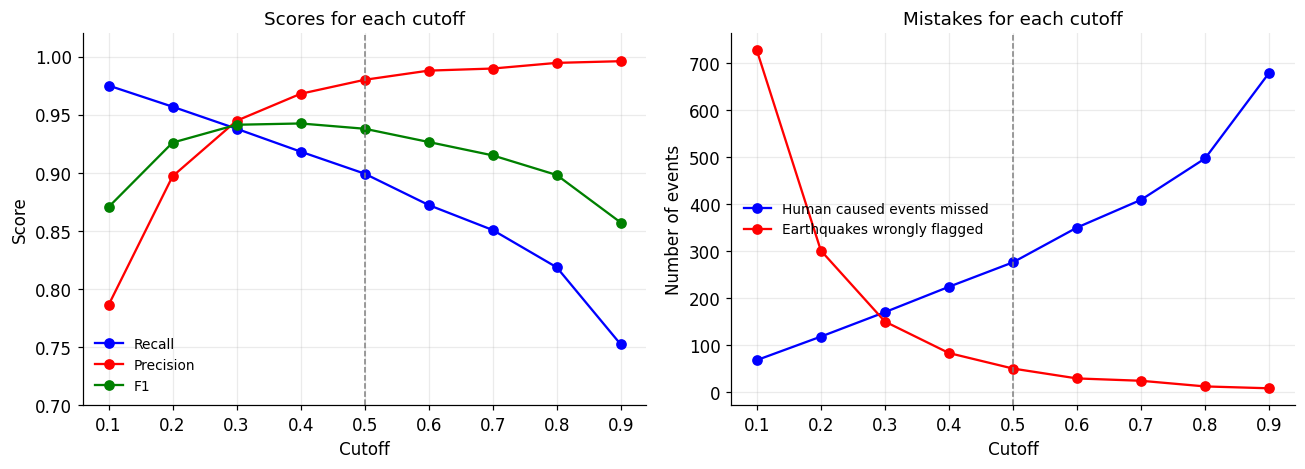

In [10]:
p_rf = probs['Random Forest']
cuts = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rows = []
for c in cuts:
    yhat = (p_rf >= c).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_all, yhat).ravel()
    rows.append([c, recall_score(y_all, yhat), precision_score(y_all, yhat), f1_score(y_all, yhat), fn, fp])
cut_df = pd.DataFrame(rows, columns=['cutoff', 'recall', 'precision', 'F1', 'missed', 'false_alarms'])
print(cut_df.round(3).to_string(index=False))
best_cut = cut_df.loc[cut_df['F1'].idxmax(), 'cutoff']
print('Cutoff with the highest F1:', best_cut)

rows = []
for c in [0.3, 0.5]:
    for yr in YEARS:
        te = df[df['year'] == yr]
        yhat = (p_rf[te.index] >= c).astype(int)
        rows.append([c, yr, recall_score(te['is_manmade'], yhat), precision_score(te['is_manmade'], yhat)])
cy = pd.DataFrame(rows, columns=['cutoff', 'year', 'recall', 'precision'])
print(cy.pivot(index='year', columns='cutoff', values=['recall', 'precision']).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ax[0].plot(cut_df['cutoff'], cut_df['recall'], marker='o', color=NAT, label='Recall')
ax[0].plot(cut_df['cutoff'], cut_df['precision'], marker='o', color=MAN, label='Precision')
ax[0].plot(cut_df['cutoff'], cut_df['F1'], marker='o', color=NEU, label='F1')
ax[0].axvline(0.5, color=GRY, ls='--', lw=1)
ax[0].set_xlabel('Cutoff'); ax[0].set_ylabel('Score'); ax[0].set_ylim(0.7, 1.02)
ax[0].set_title('Scores for each cutoff'); ax[0].legend(fontsize=9)
ax[1].plot(cut_df['cutoff'], cut_df['missed'], marker='o', color=NAT, label='Human caused events missed')
ax[1].plot(cut_df['cutoff'], cut_df['false_alarms'], marker='o', color=MAN, label='Earthquakes wrongly flagged')
ax[1].axvline(0.5, color=GRY, ls='--', lw=1)
ax[1].set_xlabel('Cutoff'); ax[1].set_ylabel('Number of events')
ax[1].set_title('Mistakes for each cutoff'); ax[1].legend(fontsize=9)
plt.tight_layout(); save('fig02_cutoff')

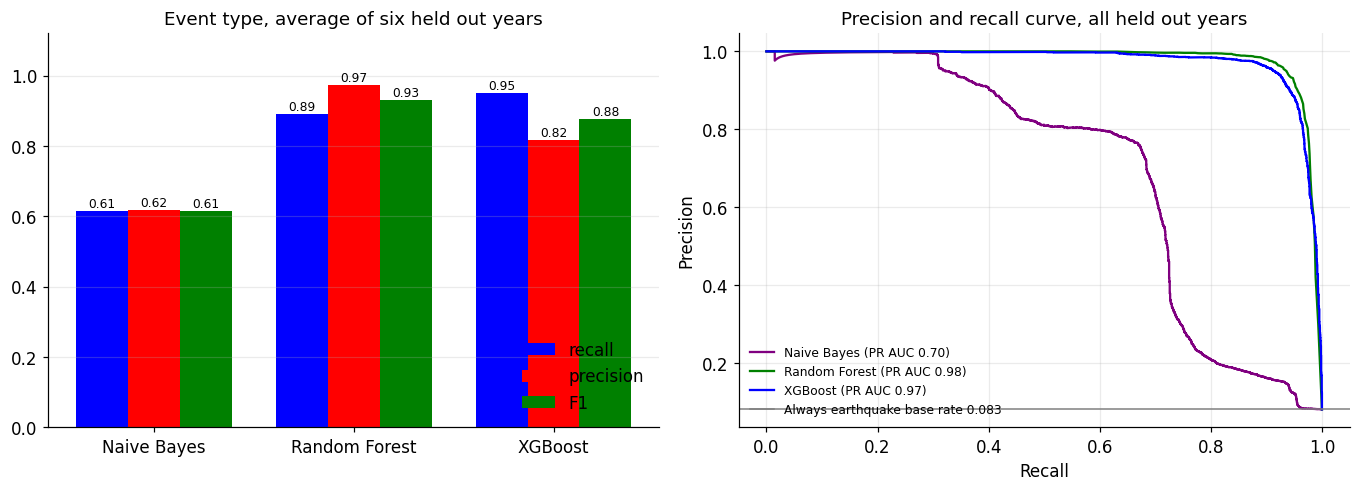

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
mods = ['Naive Bayes', 'Random Forest', 'XGBoost']
w = 0.26
for j, (m, c) in enumerate(zip(['recall', 'precision', 'F1'], [NAT, MAN, NEU])):
    vals = [type_year[type_year['model'] == k][m].mean() for k in mods]
    ax[0].bar(np.arange(3) + (j - 1) * w, vals, w, color=c, label=m)
    for i, v in enumerate(vals):
        ax[0].text(i + (j - 1) * w, v + 0.01, f'{v:.2f}', ha='center', fontsize=8)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(mods); ax[0].set_ylim(0, 1.12)
ax[0].set_title('Event type, average of six held out years'); ax[0].legend(loc='lower right'); ax[0].grid(axis='x', alpha=0)
for name, c in [('Naive Bayes', PUR), ('Random Forest', NEU), ('XGBoost', NAT)]:
    p, r, _ = precision_recall_curve(y_all, probs[name])
    ax[1].plot(r, p, color=c, label=f'{name} (PR AUC {average_precision_score(y_all, probs[name]):.2f})')
ax[1].axhline(y_all.mean(), color=GRY, lw=1, label=f'Always earthquake base rate {y_all.mean():.3f}')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Precision and recall curve, all held out years')
ax[1].legend(fontsize=8, loc='lower left')
plt.tight_layout(); save('fig03_type_models')

Human caused events: 2741  found: 2465  missed: 276
Missed events with a probability between 0.3 and 0.5: 106  below 0.1: 68

Median of each variable
           missed   found
depth       -0.49    0.00
mag          2.13    2.70
longitude -117.17 -108.71
latitude    35.49   40.31
hour        19.00   20.00

By KMeans group
       human_caused  missed  percent_missed
group                                      
1               119      32            26.9
2               261      40            15.3
3                24      20            83.3
4               346     102            29.5
5                60      41            68.3
6               463      26             5.6
7               604       9             1.5
8               864       6             0.7

By year
      human_caused  missed  percent_missed
year                                      
2000           657      55             8.4
2001           831      72             8.7
2002           572      62            10.8
2003         

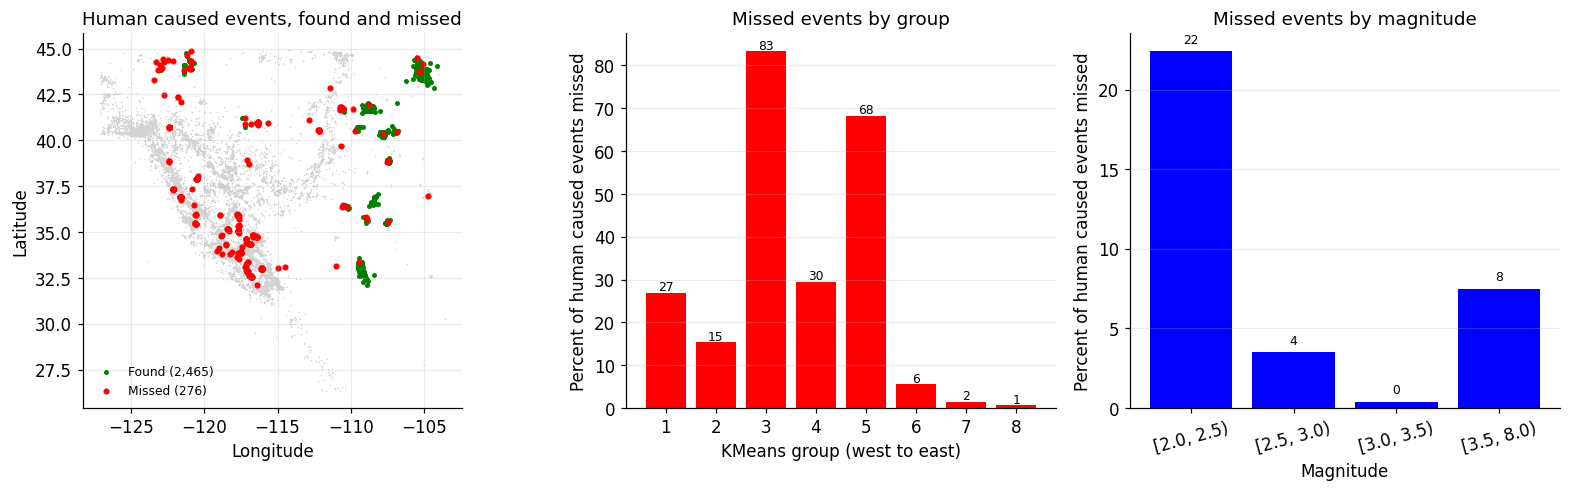

In [12]:
pred_rf = (p_rf >= 0.5).astype(int)
hum = df[df['is_manmade'] == 1].copy()
hum['prob'] = p_rf[hum.index]
hum['found'] = pred_rf[hum.index]
missed, found = hum[hum['found'] == 0], hum[hum['found'] == 1]
print('Human caused events:', len(hum), ' found:', len(found), ' missed:', len(missed))
print('Missed events with a probability between 0.3 and 0.5:', int(((missed['prob'] >= 0.3)).sum()),
      ' below 0.1:', int((missed['prob'] < 0.1).sum()))
cmp_tab = pd.DataFrame({'missed': missed[['depth', 'mag', 'longitude', 'latitude', 'hour']].median(),
                        'found': found[['depth', 'mag', 'longitude', 'latitude', 'hour']].median()}).round(2)
print('\nMedian of each variable'); print(cmp_tab)
by_group = hum.groupby('group').agg(human_caused=('found', 'size'), missed=('found', lambda s: int((s == 0).sum())))
by_group['percent_missed'] = (by_group['missed'] / by_group['human_caused'] * 100).round(1)
print('\nBy KMeans group'); print(by_group)
by_year = hum.groupby('year').agg(human_caused=('found', 'size'), missed=('found', lambda s: int((s == 0).sum())))
by_year['percent_missed'] = (by_year['missed'] / by_year['human_caused'] * 100).round(1)
print('\nBy year'); print(by_year)
mag_bins = pd.cut(hum['mag'], [2, 2.5, 3, 3.5, 8], right=False)
by_mag = hum.groupby(mag_bins, observed=True).agg(human_caused=('found', 'size'), missed=('found', lambda s: int((s == 0).sum())))
by_mag['percent_missed'] = (by_mag['missed'] / by_mag['human_caused'] * 100).round(1)
print('\nBy magnitude'); print(by_mag)
print('\nMissed events that sit in groups 1 to 5 (the earthquake regions):', int((missed['group'] <= 5).sum()))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1.3, 1, 1]})
ax[0].scatter(df.loc[df['is_manmade'] == 0, 'longitude'], df.loc[df['is_manmade'] == 0, 'latitude'], s=1, color='lightgray', linewidths=0)
ax[0].scatter(found['longitude'], found['latitude'], s=5, color=NEU, label=f'Found ({len(found):,})')
ax[0].scatter(missed['longitude'], missed['latitude'], s=9, color=MAN, label=f'Missed ({len(missed)})')
ax[0].set_xlabel('Longitude'); ax[0].set_ylabel('Latitude'); ax[0].set_title('Human caused events, found and missed')
ax[0].legend(fontsize=8, loc='lower left'); ax[0].set_aspect(1.25)
ax[1].bar(by_group.index.astype(str), by_group['percent_missed'], color=MAN)
for i, (g, v) in enumerate(zip(by_group.index, by_group['percent_missed'])):
    ax[1].text(i, v + 0.5, f'{v:.0f}', ha='center', fontsize=8)
ax[1].set_xlabel('KMeans group (west to east)'); ax[1].set_ylabel('Percent of human caused events missed')
ax[1].set_title('Missed events by group'); ax[1].grid(axis='x', alpha=0)
ax[2].bar(by_mag.index.astype(str), by_mag['percent_missed'], color=NAT)
for i, v in enumerate(by_mag['percent_missed']):
    ax[2].text(i, v + 0.5, f'{v:.0f}', ha='center', fontsize=8)
ax[2].set_xlabel('Magnitude'); ax[2].set_ylabel('Percent of human caused events missed')
ax[2].set_title('Missed events by magnitude'); ax[2].grid(axis='x', alpha=0)
plt.setp(ax[2].get_xticklabels(), rotation=15)
plt.tight_layout(); save('fig04_missed_events')

In [14]:
area_inner = GroupKFold(n_splits=3)

def tune_area(model, grid, X, y, groups, scoring):
    gs = GridSearchCV(model, grid, cv=area_inner, scoring=scoring, n_jobs=-1)
    gs.fit(X, y, groups=groups)
    return gs.best_estimator_

rows, p_depth_area, p_base_area, p_type_area = [], {}, {}, {}
for g in GROUPS:
    tr, te = df[df['group'] != g], df[df['group'] == g]
    md = tune_area(rf_reg(), grid_rf, tr[FEAT_DEPTH], tr['depth'], tr['group'], 'neg_mean_absolute_error')
    bd = DummyRegressor(strategy='median').fit(tr[FEAT_DEPTH], tr['depth'])
    mt = tune_area(rf_clf(), {'min_samples_leaf': [1, 5]}, tr[FEAT_TYPE], tr['is_manmade'], tr['group'], 'average_precision')
    pd_, pb_, pt_ = md.predict(te[FEAT_DEPTH]), bd.predict(te[FEAT_DEPTH]), mt.predict_proba(te[FEAT_TYPE])[:, 1]
    p_depth_area[g], p_base_area[g], p_type_area[g] = pd.Series(pd_, te.index), pd.Series(pb_, te.index), pd.Series(pt_, te.index)
    yh, yt = (pt_ >= 0.5).astype(int), te['is_manmade']
    rows.append([g, len(te), int(yt.sum()), mean_absolute_error(te['depth'], pd_), mean_absolute_error(te['depth'], pb_),
                 int(((yh == 1) & (yt == 1)).sum()), int(((yh == 1) & (yt == 0)).sum()), int(((yh == 0) & (yt == 1)).sum())])
area = pd.DataFrame(rows, columns=['group', 'events', 'human_caused', 'MAE_forest', 'MAE_median', 'found', 'false_alarms', 'missed'])
area['recall'] = (area['found'] / area['human_caused'].replace(0, np.nan)).round(3)
print('Leave one group out')
print(area.round(2).to_string(index=False))

pdp = pd.concat(p_depth_area.values()).sort_index()
pbp = pd.concat(p_base_area.values()).sort_index()
ptp = pd.concat(p_type_area.values()).sort_index()
print('\nDepth, all groups together. Random Forest', [round(v, 3) for v in depth_scores(df['depth'], pdp)],
      ' Baseline median', [round(v, 3) for v in depth_scores(df['depth'], pbp)])
yh = (ptp >= 0.5).astype(int)
print('Event type, all groups together: recall', round(recall_score(y_all, yh), 3), ' precision', round(precision_score(y_all, yh), 3),
      ' F1', round(f1_score(y_all, yh), 3), ' PR AUC', round(average_precision_score(y_all, ptp), 3),
      ' ROC AUC', round(roc_auc_score(y_all, ptp), 3), ' accuracy', round((yh == y_all).mean(), 3))
print('Confusion matrix (rows actual, columns predicted):'); print(confusion_matrix(y_all, yh))

Leave one group out
 group  events  human_caused  MAE_forest  MAE_median  found  false_alarms  missed  recall
     1    5769           119       10.23        6.46      0             0     119    0.00
     2    7637           261        5.53        2.64      0             0     261    0.00
     3    3871            24        5.32        3.72      0             0      24    0.00
     4    7216           346        6.76        3.94      0             0     346    0.00
     5    4896            60        2.70        3.05      0             1      60    0.00
     6    2217           463        3.50        3.77    447           645      16    0.96
     7     689           604        4.70        4.75      2             1     602    0.00
     8     886           864        4.65        5.21      6             4     858    0.01

Depth, all groups together. Random Forest [5.995, np.float64(7.822), -0.792]  Baseline median [3.961, np.float64(5.938), -0.033]
Event type, all groups together: recall 

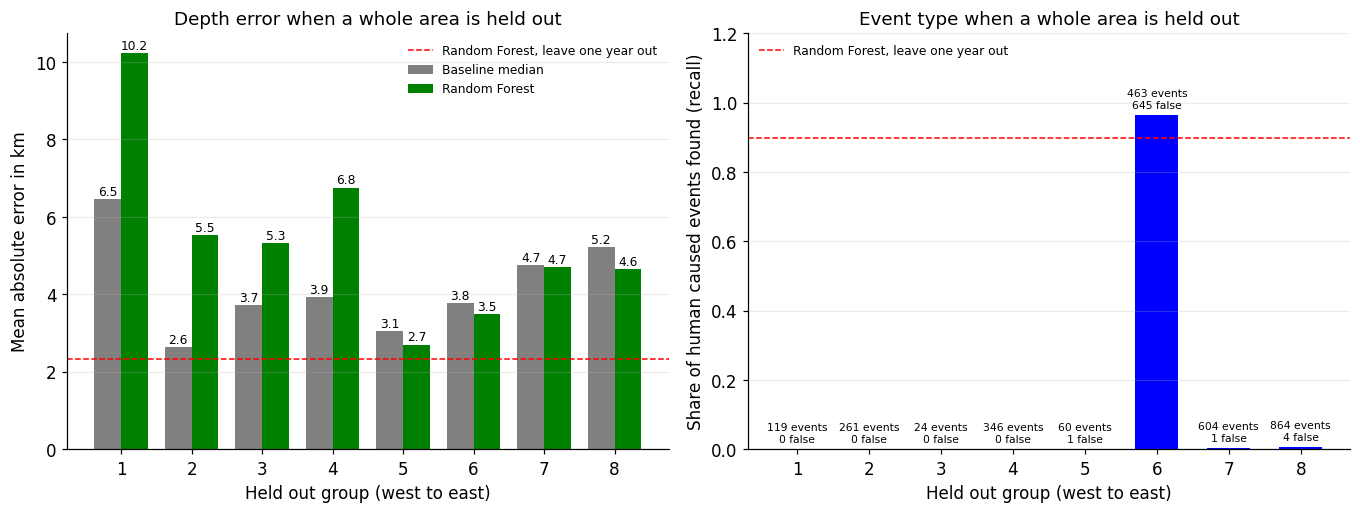

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8))
x = np.arange(len(GROUPS)); w = 0.38
ax[0].bar(x - w / 2, area['MAE_median'], w, color=GRY, label='Baseline median')
ax[0].bar(x + w / 2, area['MAE_forest'], w, color=NEU, label='Random Forest')
for i, (a, b) in enumerate(zip(area['MAE_median'], area['MAE_forest'])):
    ax[0].text(i - w / 2, a + 0.1, f'{a:.1f}', ha='center', fontsize=8)
    ax[0].text(i + w / 2, b + 0.1, f'{b:.1f}', ha='center', fontsize=8)
ax[0].axhline(depth_year[depth_year['model'] == 'Random Forest, six predictors']['MAE'].mean(), color=MAN, ls='--', lw=1,
              label='Random Forest, leave one year out')
ax[0].set_xticks(x); ax[0].set_xticklabels(GROUPS); ax[0].set_xlabel('Held out group (west to east)')
ax[0].set_ylabel('Mean absolute error in km'); ax[0].set_title('Depth error when a whole area is held out')
ax[0].legend(fontsize=8); ax[0].grid(axis='x', alpha=0)
rec = area['recall'].fillna(0)
ax[1].bar(x, rec, color=NAT, width=0.6)
for i, (r, n, fa) in enumerate(zip(area['recall'], area['human_caused'], area['false_alarms'])):
    ax[1].text(i, (0 if np.isnan(r) else r) + 0.02, f'{n} events\n{fa} false', ha='center', fontsize=7)
ax[1].axhline(recall_score(y_all, (probs['Random Forest'] >= 0.5).astype(int)), color=MAN, ls='--', lw=1,
              label='Random Forest, leave one year out')
ax[1].set_ylim(0, 1.2); ax[1].set_xticks(x); ax[1].set_xticklabels(GROUPS)
ax[1].set_xlabel('Held out group (west to east)'); ax[1].set_ylabel('Share of human caused events found (recall)')
ax[1].set_title('Event type when a whole area is held out'); ax[1].legend(fontsize=8, loc='upper left'); ax[1].grid(axis='x', alpha=0)
plt.tight_layout(); save('fig05_area_holdout')

In [16]:
depth_year.to_csv('results_depth_year.csv', index=False)
depth_eq.to_csv('results_depth_earthquakes_only.csv', index=False)
type_year.to_csv('results_type_year.csv', index=False)
cut_df.to_csv('results_cutoff.csv', index=False)
area.to_csv('results_area_holdout.csv', index=False)
import shutil
shutil.make_archive('figures_results', 'zip', FIG)
try:
    from google.colab import files
    files.download('figures_results.zip')
except Exception:
    print('Saved figures_results.zip in the current folder')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>